[INFO] Top 3 metastatic sites:
  metastatic_site  n_samples
0           liver         24
1            bone         14
2           brain         12
[INFO] Found 262 metric files.

[INFO] Processing site: liver | n metadata samples = 24
  Processing sample: TP21-M732 -> TP21-M732.metrics.txt
  Processing sample: TP20-M260 -> TP20-M260.metrics.txt
  Processing sample: TP19-M879 -> TP19-M879.metrics.txt
  Processing sample: TP20-M529 -> TP20-M529.metrics.txt
  Processing sample: TP18-M624 -> TP18-M624.metrics.txt
  Processing sample: TP19-M210 -> TP19-M210.metrics.txt
  Processing sample: TP22-M243 -> TP22-M243.metrics.txt
  Processing sample: TP18-M578 -> TP18-M578.metrics.txt
  Processing sample: TP21-M167 -> TP21-M167.metrics.txt
  Processing sample: TP19-M299 -> TP19-M299.metrics.txt
  Processing sample: TP20-M99 -> TP20-M99.metrics.txt
  Processing sample: TP21-M844 -> TP21-M844.metrics.txt
  Processing sample: TP22-M310 -> TP22-M310.metrics.txt
  Processing sample: TP21-M37 -> TP21-M

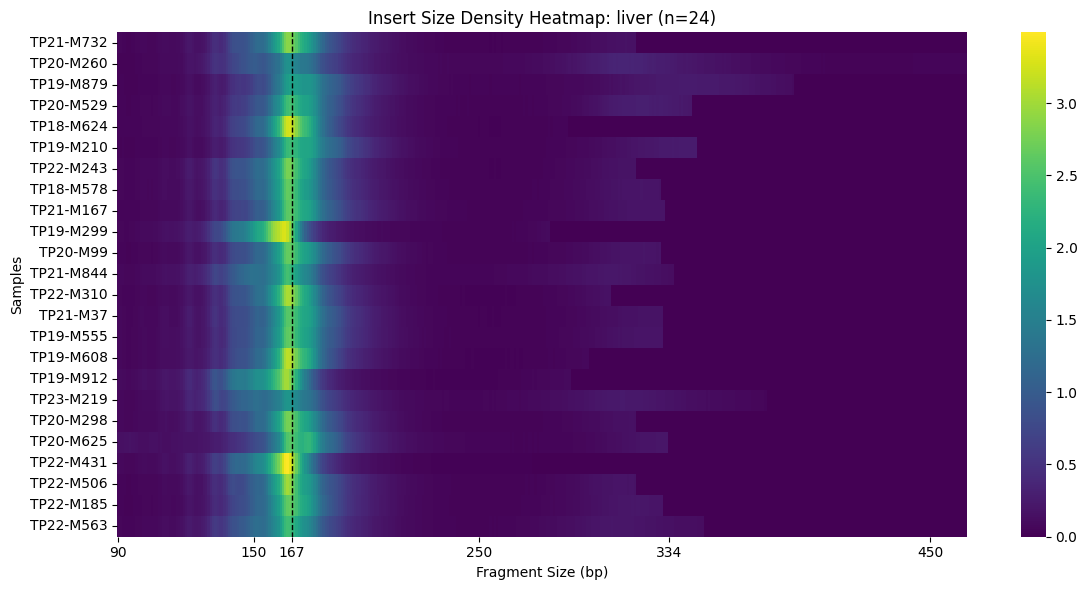

[INFO] Saved heatmap for liver

[INFO] Processing site: bone | n metadata samples = 14
  Processing sample: TP18-M772 -> TP18-M772.metrics.txt
  Processing sample: TP23-M29 -> TP23-M29.metrics.txt
  Processing sample: TP21-M249 -> TP21-M249.metrics.txt
  Processing sample: TP21-M44 -> TP21-M44.metrics.txt
  Processing sample: TP20-M240 -> TP20-M240.metrics.txt
  Processing sample: TP19-M30 -> TP19-M30.metrics.txt
  Processing sample: TP21-M92 -> TP21-M92.metrics.txt
  Processing sample: TP21-M97 -> TP21-M97.metrics.txt
  Processing sample: TP20-M531 -> TP20-M531.metrics.txt
  Processing sample: TP21-M123 -> TP21-M123.metrics.txt
  Processing sample: TP21-M193 -> TP21-M193.metrics.txt
  Processing sample: TP22-M481 -> TP22-M481.metrics.txt
  Processing sample: TP22-M422 -> TP22-M422.metrics.txt
  Processing sample: TP23-M376 -> TP23-M376.metrics.txt
[INFO] Saved proportions for bone
[INFO] Saved density matrix for bone


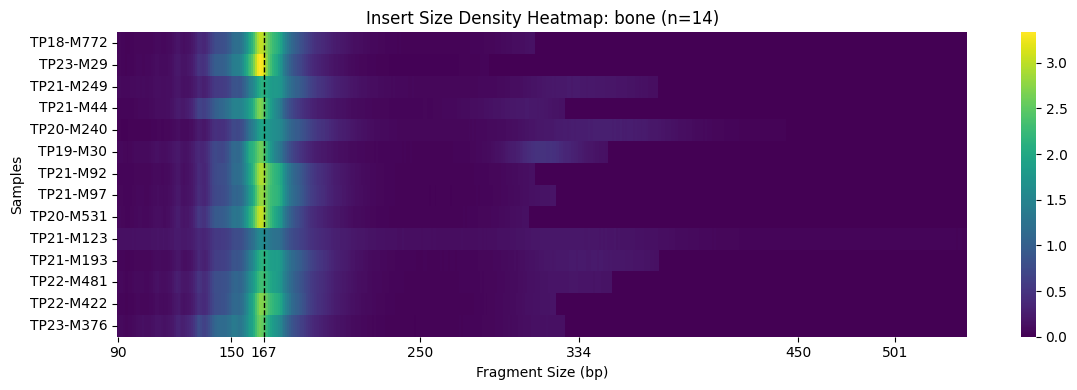

[INFO] Saved heatmap for bone

[INFO] Processing site: brain | n metadata samples = 12
  Processing sample: TP21-M565 -> TP21-M565.metrics.txt
  Processing sample: TP19-M917 -> TP19-M917.metrics.txt
  Processing sample: TP19-M527 -> TP19-M527.metrics.txt
  Processing sample: TP18-M677 -> TP18-M677.metrics.txt
  Processing sample: TP20-M291 -> TP20-M291.metrics.txt
  Processing sample: TP21-M14 -> TP21-M14.metrics.txt
  Processing sample: TP22-M164 -> TP22-M164.metrics.txt
  Processing sample: TP21-M768 -> TP21-M768.metrics.txt
  Processing sample: TP21-M625 -> TP21-M625.metrics.txt
  Processing sample: TP21-M431 -> TP21-M431.metrics.txt
  Processing sample: TP23-M100 -> TP23-M100.metrics.txt
  Processing sample: TP22-M626 -> TP22-M626.metrics.txt
[INFO] Saved proportions for brain
[INFO] Saved density matrix for brain


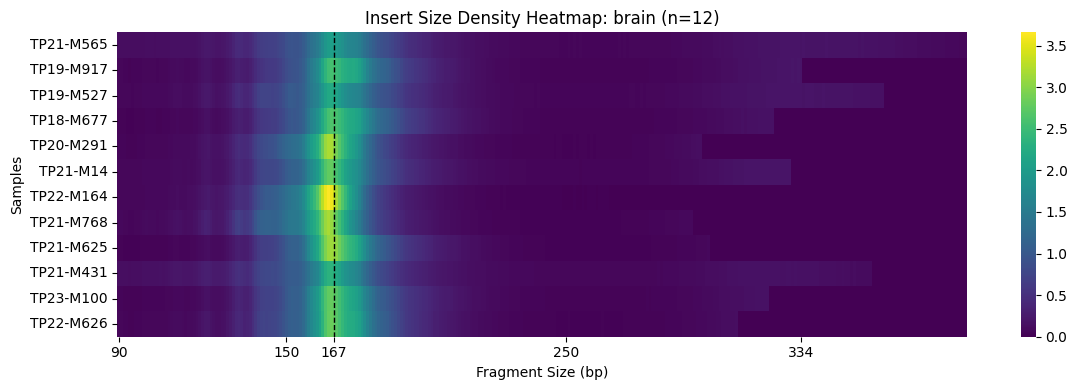

[INFO] Saved heatmap for brain

[INFO] Combined fragment proportions saved.


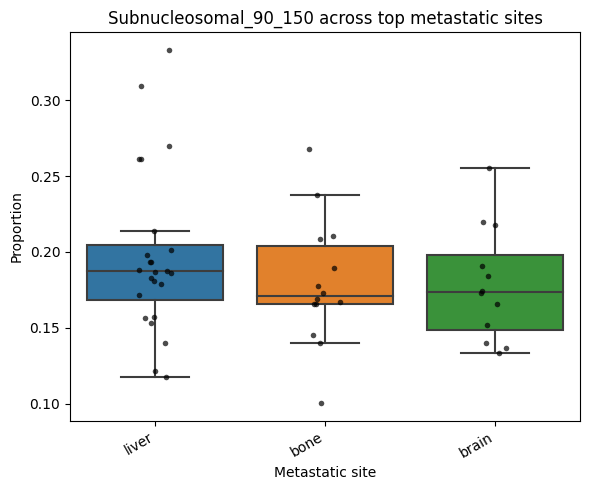

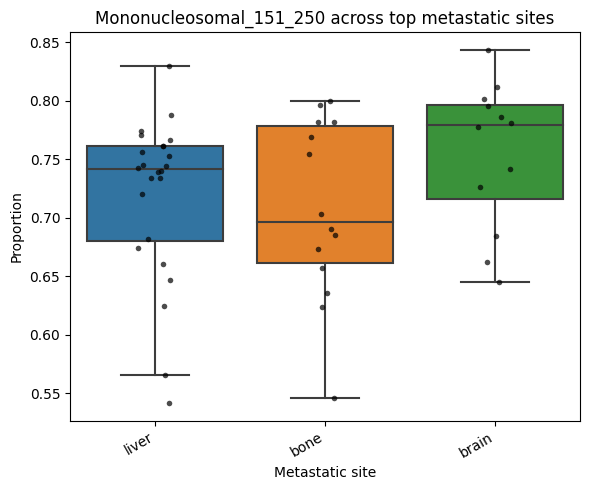

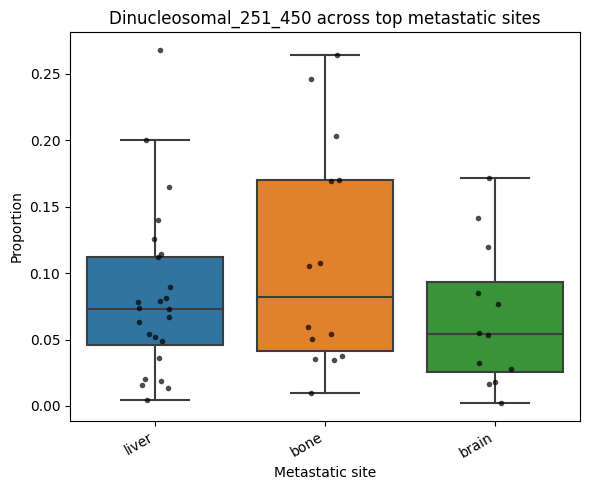

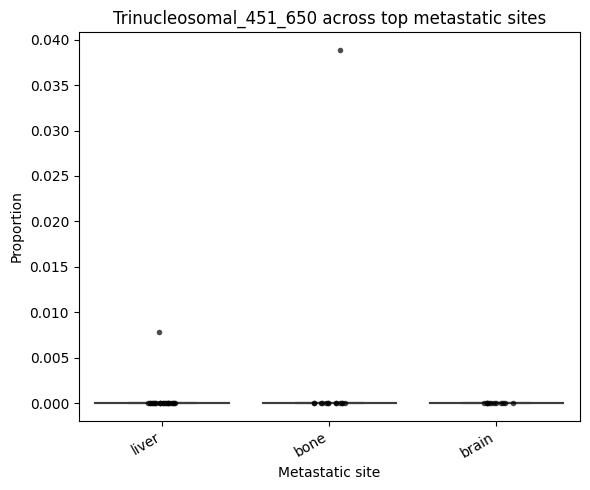

[INFO] Boxplots saved.
[INFO] Kruskal-Wallis results saved.
                    metric  n_liver  n_bone  n_brain  kruskal_stat   p_value  \
0    Subnucleosomal_90_150       24      14       12      1.802493  0.406063   
1  Mononucleosomal_151_250       24      14       12      3.325042  0.189660   
2    Dinucleosomal_251_450       24      14       12      1.541064  0.462767   
3   Trinucleosomal_451_650       24      14       12      0.875790  0.645394   

   p_adj_BH  significant_BH_0.05  
0  0.617022                False  
1  0.617022                False  
2  0.617022                False  
3  0.645394                False  
[INFO] Pairwise Mann-Whitney results saved.
                     metric  site1  site2  n_site1  n_site2  mannwhitney_stat  \
0     Subnucleosomal_90_150  liver   bone       24       14             203.0   
1     Subnucleosomal_90_150  liver  brain       24       12             178.0   
2     Subnucleosomal_90_150   bone  brain       14       12              85.0

In [3]:
import os
import glob
import io
import re
from itertools import combinations

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import kruskal, mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ================================
# CONFIGURATION
# ================================

metrics_dir = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/Fragmentation_analysis/Global_Fragment_analysis/Result"
meta_file = "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/Broad/NST/End_motif/metastasis_site_summary/metastasis_single_site_one_per_bios_site.csv"

output_base = os.path.join(metrics_dir, "Top3_metastatic_site_fragmentation")
os.makedirs(output_base, exist_ok=True)

alpha = 0.05
display_plots = True   # set False if you only want to save plots

# ================================
# HELPERS
# ================================

def sanitize_name(x):
    """Make safe folder/file names."""
    x = str(x).strip().lower()
    x = re.sub(r"[^a-z0-9]+", "_", x)
    x = re.sub(r"_+", "_", x).strip("_")
    return x

def find_metric_file(sample_id, file_dict):
    """
    Match sample_id to metrics file.
    First try exact basename match, then substring match.
    """
    if sample_id in file_dict:
        return file_dict[sample_id]

    candidates = [fp for name, fp in file_dict.items() if sample_id in name]
    if len(candidates) == 1:
        return candidates[0]
    elif len(candidates) > 1:
        print(f"[WARN] Multiple metric files matched sample {sample_id}; skipping ambiguous match.")
        return None
    else:
        print(f"[WARN] No metric file found for sample {sample_id}")
        return None

def parse_metrics_file(file_path):
    """Read histogram section and return cleaned histogram dataframe."""
    with open(file_path, "r") as f:
        lines = f.readlines()

    histogram_start = next((i for i, line in enumerate(lines) if line.startswith("## HISTOGRAM")), None)
    if histogram_start is None:
        print(f"[WARN] No histogram section found in {file_path}")
        return None

    histogram_section = lines[histogram_start + 1:]

    try:
        histogram_df = pd.read_csv(io.StringIO("\n".join(histogram_section)), sep="\t", comment="#")
    except pd.errors.EmptyDataError:
        print(f"[WARN] Empty histogram data in {file_path}")
        return None

    required_cols = {"insert_size", "All_Reads.fr_count"}
    if histogram_df.empty or not required_cols.issubset(histogram_df.columns):
        print(f"[WARN] Missing required histogram columns in {file_path}")
        return None

    histogram_df["insert_size"] = pd.to_numeric(histogram_df["insert_size"], errors="coerce")
    histogram_df["All_Reads.fr_count"] = pd.to_numeric(histogram_df["All_Reads.fr_count"], errors="coerce")
    histogram_df = histogram_df.dropna(subset=["insert_size", "All_Reads.fr_count"])

    # Keep insert sizes >= 90
    histogram_df = histogram_df[histogram_df["insert_size"] >= 90].copy()
    if histogram_df.empty:
        print(f"[WARN] No usable insert sizes >=90 in {file_path}")
        return None

    total_counts = histogram_df["All_Reads.fr_count"].sum()
    if total_counts == 0:
        print(f"[WARN] Total counts = 0 in {file_path}")
        return None

    histogram_df["density"] = (histogram_df["All_Reads.fr_count"] / total_counts) * 100
    return histogram_df

def compute_fragment_proportions(histogram_df):
    total_counts = histogram_df["All_Reads.fr_count"].sum()

    sub_nuc = histogram_df[
        (histogram_df["insert_size"] >= 90) & (histogram_df["insert_size"] <= 150)
    ]["All_Reads.fr_count"].sum()

    mono_nuc = histogram_df[
        (histogram_df["insert_size"] >= 151) & (histogram_df["insert_size"] <= 250)
    ]["All_Reads.fr_count"].sum()

    di_nuc = histogram_df[
        (histogram_df["insert_size"] >= 251) & (histogram_df["insert_size"] <= 450)
    ]["All_Reads.fr_count"].sum()

    tri_nuc = histogram_df[
        (histogram_df["insert_size"] >= 451) & (histogram_df["insert_size"] <= 650)
    ]["All_Reads.fr_count"].sum()

    return {
        "Subnucleosomal_90_150": sub_nuc / total_counts,
        "Mononucleosomal_151_250": mono_nuc / total_counts,
        "Dinucleosomal_251_450": di_nuc / total_counts,
        "Trinucleosomal_451_650": tri_nuc / total_counts,
    }

def plot_heatmap(combined_data, site_name, out_png, display_plots=True):
    if combined_data.empty:
        print(f"[WARN] Empty matrix for {site_name}; skipping heatmap.")
        return

    combined_data = combined_data.copy()
    combined_data = combined_data.reindex(sorted(combined_data.columns), axis=1)
    combined_data = combined_data.fillna(0)
    combined_data.columns = combined_data.columns.astype(int)

    plt.figure(figsize=(12, max(4, 0.25 * combined_data.shape[0])))

    sns.heatmap(
        combined_data,
        cmap="viridis",
        linewidths=0.0,
        yticklabels=combined_data.index if combined_data.shape[0] <= 50 else False
    )

    plt.title(f"Insert Size Density Heatmap: {site_name} (n={combined_data.shape[0]})")
    plt.xlabel("Fragment Size (bp)")
    plt.ylabel("Samples")

    desired_ticks = [90, 150, 167, 250, 334, 450, 501, 650]
    available_ticks = [x for x in desired_ticks if x in combined_data.columns]
    tick_positions = [combined_data.columns.get_loc(x) + 0.5 for x in available_ticks]
    plt.xticks(ticks=tick_positions, labels=available_ticks, rotation=0)

    if 167 in combined_data.columns:
        plt.axvline(
            x=combined_data.columns.get_loc(167) + 0.5,
            linewidth=1,
            color="black",
            alpha=1,
            linestyle="--"
        )

    plt.tight_layout()
    plt.savefig(out_png, dpi=300, bbox_inches="tight")

    if display_plots:
        plt.show()

    plt.close()

def plot_boxplots(long_df, out_dir, display_plots=True):
    metrics = [
        "Subnucleosomal_90_150",
        "Mononucleosomal_151_250",
        "Dinucleosomal_251_450",
        "Trinucleosomal_451_650"
    ]

    for metric in metrics:
        plt.figure(figsize=(6, 5))
        sns.boxplot(data=long_df, x="metastatic_site", y=metric, showfliers=False)
        sns.stripplot(data=long_df, x="metastatic_site", y=metric, color="black", alpha=0.7, size=4)
        plt.title(f"{metric} across top metastatic sites")
        plt.xlabel("Metastatic site")
        plt.ylabel("Proportion")
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
        plt.savefig(os.path.join(out_dir, f"{metric}.boxplot.png"), dpi=300, bbox_inches="tight")

        if display_plots:
            plt.show()

        plt.close()

# ================================
# LOAD METADATA
# ================================

meta = pd.read_csv(meta_file)

# Clean columns
meta["id"] = meta["id"].astype(str).str.strip()
meta["metastatic_sites"] = meta["metastatic_sites"].astype(str).str.strip()

# Drop duplicate sample-site rows if present
meta = meta.drop_duplicates(subset=["id", "metastatic_sites"]).copy()

# Top 3 metastatic sites by sample count
site_counts = (
    meta["metastatic_sites"]
    .value_counts()
    .reset_index()
)
site_counts.columns = ["metastatic_site", "n_samples"]

top3_sites = site_counts.head(3)["metastatic_site"].tolist()

site_counts.to_csv(os.path.join(output_base, "top3_site_counts.csv"), index=False)
print("[INFO] Top 3 metastatic sites:")
print(site_counts.head(3))

meta_top3 = meta[meta["metastatic_sites"].isin(top3_sites)].copy()

# ================================
# INDEX METRIC FILES
# ================================

file_paths = glob.glob(os.path.join(metrics_dir, "*.metrics.txt"))
file_dict = {
    os.path.basename(fp).replace(".metrics.txt", ""): fp
    for fp in file_paths
}

print(f"[INFO] Found {len(file_dict)} metric files.")

# ================================
# RUN SITE-WISE ANALYSIS
# ================================

all_fragment_rows = []

for site in top3_sites:
    site_safe = sanitize_name(site)
    site_outdir = os.path.join(output_base, site_safe)
    os.makedirs(site_outdir, exist_ok=True)

    site_meta = meta_top3[meta_top3["metastatic_sites"] == site].copy()
    sample_ids = site_meta["id"].tolist()

    print(f"\n[INFO] Processing site: {site} | n metadata samples = {len(sample_ids)}")

    combined_data = pd.DataFrame()
    fragment_proportions = {}
    matched_samples = []

    for sample_id in sample_ids:
        file_path = find_metric_file(sample_id, file_dict)
        if file_path is None:
            continue

        print(f"  Processing sample: {sample_id} -> {os.path.basename(file_path)}")
        histogram_df = parse_metrics_file(file_path)
        if histogram_df is None:
            continue

        props = compute_fragment_proportions(histogram_df)
        fragment_proportions[sample_id] = props
        matched_samples.append(sample_id)

        pivot_df = histogram_df.pivot_table(index=None, columns="insert_size", values="density")
        pivot_df.index = [sample_id]
        combined_data = pd.concat([combined_data, pivot_df])

        row = {
            "Sample": sample_id,
            "metastatic_site": site,
            **props
        }
        all_fragment_rows.append(row)

    # Save sample tracking
    pd.DataFrame({
        "Sample": sample_ids,
        "matched_metric_file": [find_metric_file(x, file_dict) for x in sample_ids]
    }).to_csv(os.path.join(site_outdir, f"{site_safe}.sample_matching.csv"), index=False)

    # Save proportions
    proportion_df = pd.DataFrame.from_dict(fragment_proportions, orient="index").reset_index()
    if not proportion_df.empty:
        proportion_df.rename(columns={"index": "Sample"}, inplace=True)
        proportion_df["metastatic_site"] = site
        proportion_df.to_csv(
            os.path.join(site_outdir, f"{site_safe}.fragment_size_proportions.csv"),
            index=False
        )
        print(f"[INFO] Saved proportions for {site}")
    else:
        print(f"[WARN] No valid proportion data for {site}")

    # Save density matrix
    if not combined_data.empty:
        combined_data = combined_data.reindex(sorted(combined_data.columns), axis=1)
        combined_data = combined_data.fillna(0)
        combined_data.to_csv(os.path.join(site_outdir, f"{site_safe}.insert_size_density_matrix.csv"))
        print(f"[INFO] Saved density matrix for {site}")

        # Heatmap
        plot_heatmap(
            combined_data=combined_data,
            site_name=site,
            out_png=os.path.join(site_outdir, f"{site_safe}.density_heatmap.png"),
            display_plots=display_plots
        )
        print(f"[INFO] Saved heatmap for {site}")
    else:
        print(f"[WARN] No density matrix generated for {site}")

# ================================
# COMBINED TOP3 OUTPUT
# ================================

all_props_df = pd.DataFrame(all_fragment_rows)

if all_props_df.empty:
    raise ValueError("No valid fragment proportion data were generated for the top 3 metastatic sites.")

all_props_df.to_csv(os.path.join(output_base, "top3_sites_fragment_proportions_combined.csv"), index=False)
print(f"\n[INFO] Combined fragment proportions saved.")

plot_boxplots(all_props_df, output_base, display_plots=display_plots)
print("[INFO] Boxplots saved.")

# ================================
# SIGNIFICANCE TESTING
# ================================

metrics = [
    "Subnucleosomal_90_150",
    "Mononucleosomal_151_250",
    "Dinucleosomal_251_450",
    "Trinucleosomal_451_650"
]

# ---- Kruskal-Wallis across the 3 sites ----
kw_results = []

for metric in metrics:
    group_data = []
    group_ns = {}

    for site in top3_sites:
        vals = all_props_df.loc[all_props_df["metastatic_site"] == site, metric].dropna().tolist()
        group_ns[site] = len(vals)
        if len(vals) > 0:
            group_data.append(vals)

    usable = all(
        len(all_props_df.loc[all_props_df["metastatic_site"] == site, metric].dropna()) >= 2
        for site in top3_sites
    )

    if usable:
        stat, pval = kruskal(*[
            all_props_df.loc[all_props_df["metastatic_site"] == site, metric].dropna().values
            for site in top3_sites
        ])
    else:
        stat, pval = None, None

    kw_results.append({
        "metric": metric,
        **{f"n_{sanitize_name(site)}": group_ns[site] for site in top3_sites},
        "kruskal_stat": stat,
        "p_value": pval
    })

kw_df = pd.DataFrame(kw_results)

valid_kw = kw_df["p_value"].notna()
kw_df["p_adj_BH"] = None
kw_df["significant_BH_0.05"] = None

if valid_kw.sum() > 0:
    _, qvals, _, _ = multipletests(kw_df.loc[valid_kw, "p_value"], method="fdr_bh", alpha=alpha)
    kw_df.loc[valid_kw, "p_adj_BH"] = qvals
    kw_df.loc[valid_kw, "significant_BH_0.05"] = qvals < alpha

kw_df.to_csv(os.path.join(output_base, "top3_sites_kruskal_fragment_proportions.csv"), index=False)
print("[INFO] Kruskal-Wallis results saved.")
print(kw_df)

# ---- Pairwise Mann-Whitney U ----
pairwise_results = []

for metric in metrics:
    for site1, site2 in combinations(top3_sites, 2):
        vals1 = all_props_df.loc[all_props_df["metastatic_site"] == site1, metric].dropna().values
        vals2 = all_props_df.loc[all_props_df["metastatic_site"] == site2, metric].dropna().values

        if len(vals1) >= 2 and len(vals2) >= 2:
            stat, pval = mannwhitneyu(vals1, vals2, alternative="two-sided")
        else:
            stat, pval = None, None

        pairwise_results.append({
            "metric": metric,
            "site1": site1,
            "site2": site2,
            "n_site1": len(vals1),
            "n_site2": len(vals2),
            "mannwhitney_stat": stat,
            "p_value": pval
        })

pairwise_df = pd.DataFrame(pairwise_results)

valid_pw = pairwise_df["p_value"].notna()
pairwise_df["p_adj_BH"] = None
pairwise_df["significant_BH_0.05"] = None

if valid_pw.sum() > 0:
    _, qvals_pw, _, _ = multipletests(pairwise_df.loc[valid_pw, "p_value"], method="fdr_bh", alpha=alpha)
    pairwise_df.loc[valid_pw, "p_adj_BH"] = qvals_pw
    pairwise_df.loc[valid_pw, "significant_BH_0.05"] = qvals_pw < alpha

pairwise_df.to_csv(os.path.join(output_base, "top3_sites_pairwise_mannwhitney_fragment_proportions.csv"), index=False)
print("[INFO] Pairwise Mann-Whitney results saved.")
print(pairwise_df)

print("\nDone.")
print(f"All results saved under: {output_base}")